In [1]:

%pip install -q mp-api

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.



# Phase 2: Computational Screening of Lead-Free Halide Perovskites

## Research Objective

To investigate the electronic and thermodynamic properties of selected lead-free halide perovskites and identify promising candidates for further radiation-resistance studies.

The screening considers seven compositions:

- CsPbI₃ — lead-containing reference
- Cs₃Sb₂I₉ — existing lead-free radiation-data material
- Cs₃Bi₂I₉
- Cs₂AgBiBr₆
- Cs₂AgInCl₆
- Cs₂SnI₆
- CsSnI₃

The analysis will examine calculated band gaps, band-gap character, energy above the thermodynamic convex hull, and formation energies.

Different crystal phases will be retained as separate records.

Materials screening will remain independent of the radiation-damage MLP, which was trained on only two compositions.


In [2]:

import pandas as pd
from getpass import getpass
from mp_api.client import MPRester

materials = [
    "CsPbI3",
    "Cs3Sb2I9",
    "Cs3Bi2I9",
    "Cs2AgBiBr6",
    "Cs2AgInCl6",
    "Cs2SnI6",
    "CsSnI3"
]

fields = [
    "material_id",
    "formula_pretty",
    "band_gap",
    "energy_above_hull",
    "formation_energy_per_atom",
    "is_gap_direct",
    "density"
]

api_key = getpass("Enter your Materials Project API key: ")

records = []

with MPRester(api_key) as mpr:

    for formula in materials:

        print(f"Searching: {formula}")

        documents = mpr.materials.summary.search(
            formula=formula,
            fields=fields
        )

        print(f"  Found {len(documents)} records")

        for doc in documents:
            row = {
                field: getattr(doc, field, None)
                for field in fields
            }

            row["material_id"] = str(doc.material_id)
            row["queried_formula"] = formula
            row["lead_free"] = formula != "CsPbI3"
            records.append(row)

mp_df = pd.DataFrame(records)

if mp_df.empty:
    raise ValueError("No materials were returned by the API.")

mp_df = mp_df.drop_duplicates(
    subset=["material_id"]
).reset_index(drop=True)

mp_df.to_csv(
    "Abiha_Materials_Project_Raw.csv",
    index=False
)

display(mp_df.head(15))

print("Total material records:", len(mp_df))


Searching: CsPbI3


✓ Retrieved 3 SummaryDoc documents in 0.9s

  Found 3 records
Searching: Cs3Sb2I9


✓ Retrieved 2 SummaryDoc documents in 0.3s

  Found 2 records
Searching: Cs3Bi2I9


✓ Retrieved 2 SummaryDoc documents in 0.3s

... (7 outputs left out)

✓ Retrieved 4 SummaryDoc documents in 0.3s

  Found 4 records


,material_id,formula_pretty,band_gap,energy_above_hull,formation_energy_per_atom,is_gap_direct,density,queried_formula,lead_free
0,mp-1069538,CsPbI3,1.478800,0.025049,-1.238177,True,4.844004,CsPbI3,False
1,mp-1120768,CsPbI3,1.636400,0.015823,-1.247403,True,4.746507,CsPbI3,False
2,mp-540839,CsPbI3,2.518100,0.000000,-1.263227,False,5.143480,CsPbI3,False
3,mp-23029,Cs3Sb2I9,1.867900,0.000000,-1.149382,False,4.459304,Cs3Sb2I9,True
4,mp-541014,Cs3Sb2I9,1.540600,0.003167,-1.146216,False,4.478894,Cs3Sb2I9,True
5,mp-624214,Cs3Bi2I9,2.342300,0.000867,-1.210959,False,4.761842,Cs3Bi2I9,True
6,mp-669458,Cs3Bi2I9,2.610400,0.000000,-1.211826,False,4.773292,Cs3Bi2I9,True
7,mp-1078250,Cs2AgBiBr6,1.354700,0.005525,-1.456031,False,4.652656,Cs2AgBiBr6,True
8,mp-1120775,Cs2AgBiBr6,0.000000,1.157473,-0.304083,False,3.108878,Cs2AgBiBr6,True
9,mp-1096926,Cs2InAgCl6,1.342176,0.000000,-1.739099,False,3.822943,Cs2AgInCl6,True


Total material records: 15


In [4]:

screening_df = mp_df.copy()

# Rename columns for readability
screening_df = screening_df.rename(columns={
    "band_gap": "band_gap_eV",
    "energy_above_hull": "energy_above_hull_eV_atom",
    "formation_energy_per_atom": "formation_energy_eV_atom"
})

numeric_columns = [
    "band_gap_eV",
    "energy_above_hull_eV_atom",
    "formation_energy_eV_atom",
    "density"
]

for column in numeric_columns:
    screening_df[column] = pd.to_numeric(
        screening_df[column],
        errors="coerce"
    )

# Exploratory screening criteria

screening_df["suitable_gap_range"] = (
    screening_df["band_gap_eV"]
    .between(1.0, 2.2)
    .astype("boolean")
)

screening_df["low_hull_energy"] = (
    (screening_df["energy_above_hull_eV_atom"] <= 0.05)
    .astype("boolean")
)

# Preserve missing values as unknown
screening_df.loc[
    screening_df["band_gap_eV"].isna(),
    "suitable_gap_range"
] = pd.NA

screening_df.loc[
    screening_df["energy_above_hull_eV_atom"].isna(),
    "low_hull_energy"
] = pd.NA

screening_df["initial_candidate"] = (
    screening_df["lead_free"] &
    screening_df["suitable_gap_range"].fillna(False) &
    screening_df["low_hull_energy"].fillna(False)
)

display(
    screening_df[
        [
            "material_id",
            "formula_pretty",
            "band_gap_eV",
            "energy_above_hull_eV_atom",
            "is_gap_direct",
            "initial_candidate"
        ]
    ].sort_values(
        "energy_above_hull_eV_atom"
    )
)

screening_df.to_csv(
    "Abiha_Materials_Screening.csv",
    index=False
)


,material_id,formula_pretty,band_gap_eV,energy_above_hull_eV_atom,is_gap_direct,initial_candidate
3,mp-23029,Cs3Sb2I9,1.867900,0.000000,False,True
2,mp-540839,CsPbI3,2.518100,0.000000,False,False
6,mp-669458,Cs3Bi2I9,2.610400,0.000000,False,False
9,mp-1096926,Cs2InAgCl6,1.342176,0.000000,False,True
10,mp-27636,Cs2SnI6,0.293800,0.000000,True,False
13,mp-614013,CsSnI3,0.450000,0.000000,True,False
5,mp-624214,Cs3Bi2I9,2.342300,0.000867,False,False
4,mp-541014,Cs3Sb2I9,1.540600,0.003167,False,True
11,mp-27381,CsSnI3,2.063263,0.003249,False,True
7,mp-1078250,Cs2AgBiBr6,1.354700,0.005525,False,True


In [5]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Keep lead-free materials satisfying the initial screening
candidates = screening_df[
    screening_df["initial_candidate"].fillna(False).astype(bool)
].copy()

TARGET_GAP = 1.5

candidates["gap_error"] = abs(
    candidates["band_gap_eV"] - TARGET_GAP
)

# Identify Pareto-optimal materials
def find_pareto(data):
    values = data[
        ["gap_error", "energy_above_hull_eV_atom"]
    ].to_numpy(dtype=float)

    pareto = np.ones(len(values), dtype=bool)

    for i in range(len(values)):
        for j in range(len(values)):
            if i == j:
                continue

            # Material j dominates material i
            if (
                np.all(values[j] <= values[i]) and
                np.any(values[j] < values[i])
            ):
                pareto[i] = False
                break

    return pareto


candidates["pareto_optimal"] = find_pareto(candidates)

display(
    candidates[
        [
            "material_id",
            "formula_pretty",
            "band_gap_eV",
            "energy_above_hull_eV_atom",
            "gap_error",
            "pareto_optimal"
        ]
    ].sort_values(
        ["pareto_optimal", "gap_error"],
        ascending=[False, True]
    )
)

candidates.to_csv(
    "Abiha_Pareto_Results.csv",
    index=False
)

print(
    "Pareto-optimal phases:",
    candidates["pareto_optimal"].sum()
)


,material_id,formula_pretty,band_gap_eV,energy_above_hull_eV_atom,gap_error,pareto_optimal
4,mp-541014,Cs3Sb2I9,1.540600,0.003167,0.040600,True
9,mp-1096926,Cs2InAgCl6,1.342176,0.000000,0.157824,True
7,mp-1078250,Cs2AgBiBr6,1.354700,0.005525,0.145300,False
3,mp-23029,Cs3Sb2I9,1.867900,0.000000,0.367900,False
11,mp-27381,CsSnI3,2.063263,0.003249,0.563263,False


Pareto-optimal phases: 2


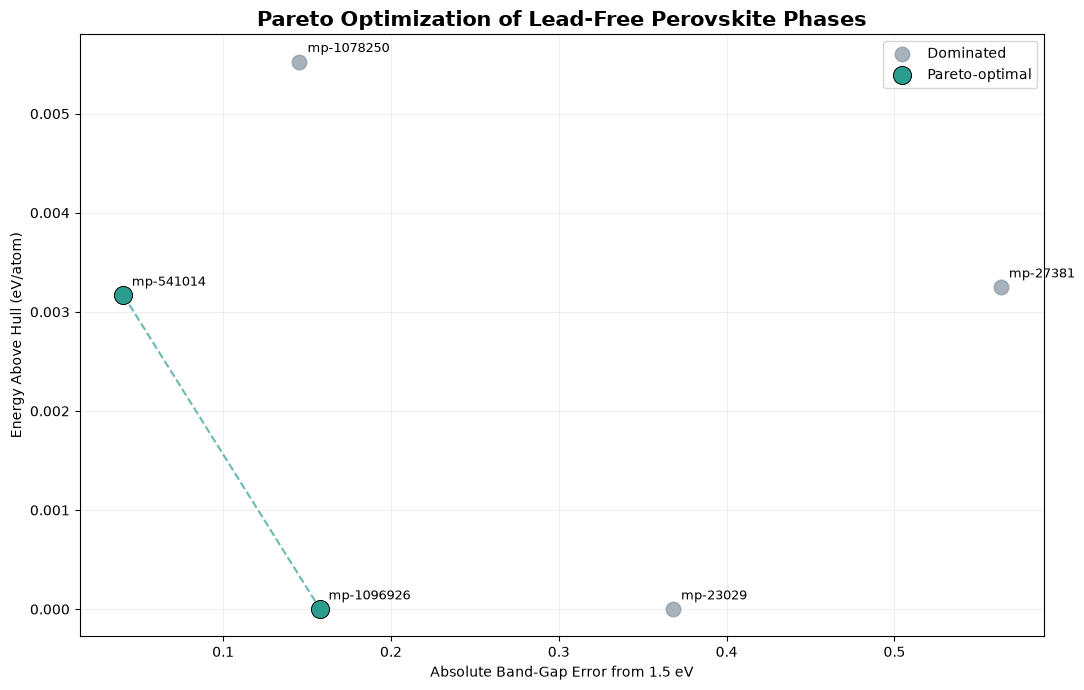

In [6]:

fig, ax = plt.subplots(figsize=(11, 7))

dominated = candidates[~candidates["pareto_optimal"]]
pareto = candidates[candidates["pareto_optimal"]]

ax.scatter(
    dominated["gap_error"],
    dominated["energy_above_hull_eV_atom"],
    color="#8899A6",
    s=110,
    label="Dominated",
    alpha=0.75
)

ax.scatter(
    pareto["gap_error"],
    pareto["energy_above_hull_eV_atom"],
    color="#2A9D8F",
    s=170,
    edgecolors="black",
    linewidths=0.7,
    label="Pareto-optimal",
    zorder=3
)

for _, row in candidates.iterrows():
    ax.annotate(
        row["material_id"],
        (
            row["gap_error"],
            row["energy_above_hull_eV_atom"]
        ),
        xytext=(6, 7),
        textcoords="offset points",
        fontsize=9
    )

front = pareto.sort_values("gap_error")

ax.plot(
    front["gap_error"],
    front["energy_above_hull_eV_atom"],
    linestyle="--",
    color="#2A9D8F",
    alpha=0.7
)

ax.set_xlabel("Absolute Band-Gap Error from 1.5 eV")
ax.set_ylabel("Energy Above Hull (eV/atom)")

ax.set_title(
    "Pareto Optimization of Lead-Free Perovskite Phases",
    fontsize=15,
    fontweight="bold"
)

ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()

plt.savefig(
    "Abiha_Pareto_Frontier.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



## Pareto Optimization of Lead-Free Perovskites

Multi-objective optimization was performed using two calculated material properties:

1. Absolute deviation from a target electronic band gap of 1.5 eV.
2. Energy above the thermodynamic convex hull.

The analysis was restricted to lead-free phase records satisfying the initial exploratory screening criteria.

### Results

Two phases were identified as non-dominated:

- Cs₃Sb₂I₉ (mp-541014)
- Cs₂AgInCl₆ (mp-1096926)

Cs₃Sb₂I₉ (mp-541014) provides a calculated band gap closer to the 1.5 eV target, whereas Cs₂AgInCl₆ (mp-1096926) has lower calculated energy above hull.

Neither phase strictly dominates the other across both objectives.

### Scientific Interpretation

The Pareto frontier identifies trade-offs between electronic band-gap suitability and calculated thermodynamic stability.

However, Pareto optimality does not imply photovoltaic efficiency, radiation resistance, or operational stability.

Both shortlisted phases have indirect calculated band gaps, which may affect their optical absorption characteristics.

Additional experimental and literature evidence is therefore necessary before making final recommendations.


In [7]:

target_gaps = [1.3, 1.5, 1.7]
hull_limits = [0.025, 0.05, 0.10]

# Start with all lead-free phases having both properties
all_lead_free = screening_df[
    screening_df["lead_free"]
].dropna(
    subset=[
        "band_gap_eV",
        "energy_above_hull_eV_atom"
    ]
).copy()

sensitivity_results = []

for gap_target in target_gaps:
    for hull_limit in hull_limits:

        subset = all_lead_free[
            all_lead_free["band_gap_eV"].between(1.0, 2.2) &
            (all_lead_free["energy_above_hull_eV_atom"] <= hull_limit)
        ].copy()

        if subset.empty:
            continue

        subset["gap_error"] = abs(
            subset["band_gap_eV"] - gap_target
        )

        subset["pareto_optimal"] = find_pareto(subset)

        for _, row in subset.iterrows():
            sensitivity_results.append({
                "material_id": row["material_id"],
                "formula": row["formula_pretty"],
                "target_gap": gap_target,
                "hull_limit": hull_limit,
                "pareto_optimal": bool(row["pareto_optimal"])
            })

sensitivity_df = pd.DataFrame(sensitivity_results)

sensitivity_df.to_csv(
    "Abiha_Pareto_Sensitivity.csv",
    index=False
)

# Count how often each phase is selected
frequency = (
    sensitivity_df
    .groupby(["material_id", "formula"])["pareto_optimal"]
    .sum()
    .reset_index(name="pareto_scenarios")
)

frequency = frequency.sort_values(
    "pareto_scenarios",
    ascending=False
)

display(frequency)


,material_id,formula,pareto_scenarios
1,mp-1096926,Cs2InAgCl6,6
4,mp-541014,Cs3Sb2I9,6
2,mp-23029,Cs3Sb2I9,3
0,mp-1078250,Cs2AgBiBr6,0
3,mp-27381,CsSnI3,0


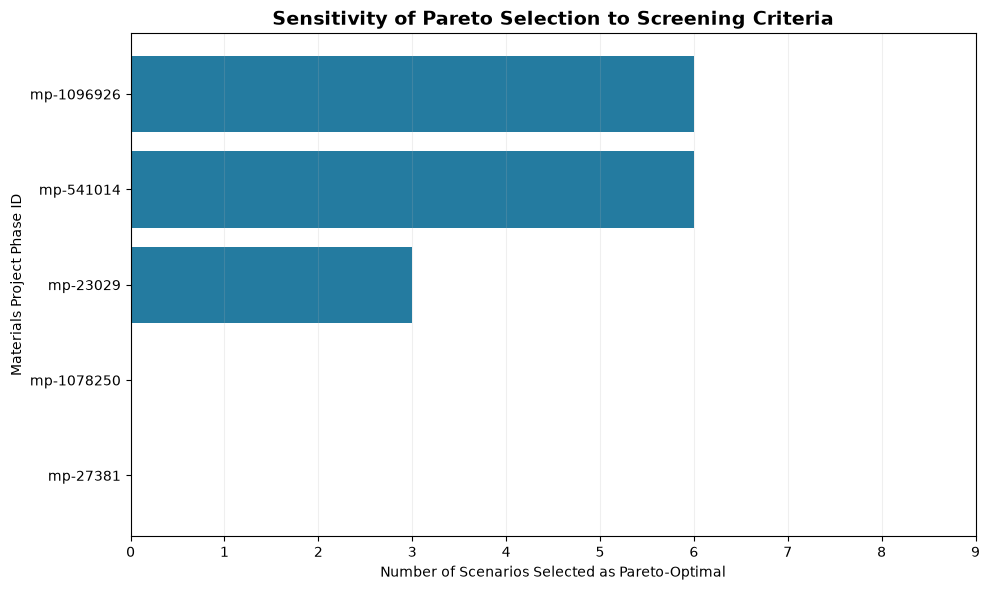

In [8]:

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    frequency["material_id"],
    frequency["pareto_scenarios"],
    color="#247BA0"
)

ax.set_xlabel("Number of Scenarios Selected as Pareto-Optimal")
ax.set_ylabel("Materials Project Phase ID")

ax.set_title(
    "Sensitivity of Pareto Selection to Screening Criteria",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlim(0, 9)
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()

plt.savefig(
    "Abiha_Pareto_Sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



## Sensitivity Analysis of Materials Prioritization

The Pareto analysis was repeated across nine combinations of band-gap targets and thermodynamic-stability thresholds.

Target band gaps of 1.3, 1.5, and 1.7 eV were investigated alongside maximum energy-above-hull thresholds of 0.025, 0.05, and 0.10 eV/atom.

The purpose was to determine whether the same materials remain non-dominated when the screening assumptions change.

A phase appearing on multiple Pareto frontiers may be considered more robust to these particular screening assumptions.

However, selection frequency is not a physical performance score or a measure of statistical confidence.

The analysis is limited to calculated electronic band gaps and thermodynamic stability. Direct versus indirect optical transitions, synthesis feasibility, experimental device performance, chemical toxicity, and radiation evidence remain separate considerations.



In [9]:

target_gaps = [1.3, 1.5, 1.7]
hull_limits = [0.0, 0.003, 0.005, 0.010, 0.025]
gap_ranges = [(1.0, 2.2), (1.2, 1.8)]

# Start with lead-free records with available properties
data = screening_df[
    screening_df["lead_free"]
].dropna(
    subset=["band_gap_eV", "energy_above_hull_eV_atom"]
).copy()

results = []

for gap_min, gap_max in gap_ranges:
    for hull_limit in hull_limits:
        for target in target_gaps:

            subset = data[
                data["band_gap_eV"].between(gap_min, gap_max) &
                (data["energy_above_hull_eV_atom"] <= hull_limit)
            ].copy()

            if subset.empty:
                continue

            subset["gap_error"] = abs(
                subset["band_gap_eV"] - target
            )

            subset["pareto_optimal"] = find_pareto(subset)

            for _, row in subset.iterrows():
                results.append({
                    "material_id": row["material_id"],
                    "formula": row["formula_pretty"],
                    "gap_range": f"{gap_min}-{gap_max}",
                    "target_gap": target,
                    "hull_limit": hull_limit,
                    "pareto_optimal": bool(row["pareto_optimal"])
                })

robustness_df = pd.DataFrame(results)

# Summarize how often each phase was eligible and selected
summary = (
    robustness_df
    .groupby(["material_id", "formula"])
    .agg(
        eligible_scenarios=("pareto_optimal", "size"),
        pareto_scenarios=("pareto_optimal", "sum")
    )
    .reset_index()
)

summary["selection_rate"] = (
    summary["pareto_scenarios"] /
    summary["eligible_scenarios"]
)

summary = summary.sort_values(
    ["pareto_scenarios", "selection_rate"],
    ascending=False
)

display(summary.round(3))

robustness_df.to_csv(
    "Abiha_Corrected_Pareto_Sensitivity.csv",
    index=False
)

summary.to_csv(
    "Abiha_Pareto_Robustness_Summary.csv",
    index=False
)

print("Total screening scenarios: 30")
print("Scenarios with eligible materials:",
      robustness_df[
          ["gap_range", "target_gap", "hull_limit"]
      ].drop_duplicates().shape[0])


,material_id,formula,eligible_scenarios,pareto_scenarios,selection_rate
1,mp-1096926,Cs2InAgCl6,30,25,0.833
4,mp-541014,Cs3Sb2I9,18,12,0.667
2,mp-23029,Cs3Sb2I9,15,5,0.333
0,mp-1078250,Cs2AgBiBr6,12,0,0.000
3,mp-27381,CsSnI3,9,0,0.000


Total screening scenarios: 30
Scenarios with eligible materials: 30


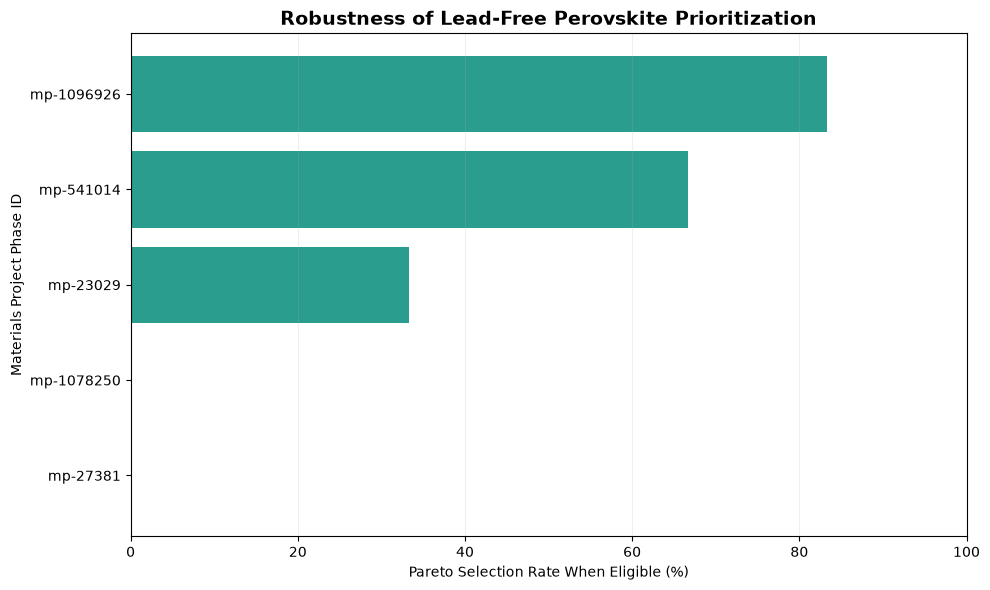

In [10]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    summary["material_id"],
    summary["selection_rate"] * 100,
    color="#2A9D8F"
)

ax.set_xlabel("Pareto Selection Rate When Eligible (%)")
ax.set_ylabel("Materials Project Phase ID")
ax.set_xlim(0, 100)

ax.set_title(
    "Robustness of Lead-Free Perovskite Prioritization",
    fontsize=14,
    fontweight="bold"
)

ax.invert_yaxis()
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()

plt.savefig(
    "Abiha_Pareto_Robustness.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



## Robustness of Multi-Objective Materials Screening

The initial Pareto analysis was extended to investigate how changes in screening assumptions affect the selection of candidate phases.

Thirty scenarios were defined using:

- Target band gaps of 1.3, 1.5, and 1.7 eV.
- Maximum energies above hull of 0, 0.003, 0.005, 0.010, and 0.025 eV/atom.
- Initial band-gap ranges of 1.0–2.2 and 1.2–1.8 eV.

Pareto optimization was repeated independently for each scenario containing eligible materials.

Selection frequency and selection rate were calculated for each phase.

Selection rate was defined as the proportion of eligible scenarios in which the phase was Pareto-optimal.

This distinction is important because not every phase satisfies the eligibility criteria in every scenario.

The analysis evaluates sensitivity to the chosen screening assumptions. It does not establish statistical confidence, physical stability, photovoltaic efficiency, or radiation resistance.

The results will inform the selection of phases for further literature-based evaluation.



## Robustness of Lead-Free Perovskite Screening

A sensitivity analysis was conducted across 30 combinations of target band gap, energy-above-hull threshold, and band-gap inclusion range.

Five lead-free crystal-phase records were assessed.

### Key Results

Cs₂AgInCl₆ (mp-1096926) was Pareto-optimal in 25 of 30 eligible scenarios (83.3%).

Cs₃Sb₂I₉ (mp-541014) was Pareto-optimal in 12 of 18 eligible scenarios (66.7%).

The second Cs₃Sb₂I₉ phase (mp-23029) was selected in 5 of 15 eligible scenarios (33.3%).

Cs₂AgBiBr₆ (mp-1078250) and CsSnI₃ (mp-27381) were not Pareto-optimal under the investigated conditions.

### Interpretation

The results indicate that Cs₂AgInCl₆ (mp-1096926) and Cs₃Sb₂I₉ (mp-541014) exhibit comparatively robust trade-offs between calculated band-gap suitability and thermodynamic stability.

However, six screening scenarios contained only one eligible phase, making Pareto selection automatic in those cases.

Selection frequency therefore represents sensitivity to specified screening assumptions rather than statistical confidence or demonstrated material performance.

### Research Implications

The two leading phases are prioritized for further investigation of optical properties, experimental photovoltaic evidence, and radiation response.

The computational screening does not establish radiation resistance, operational stability, or suitability for space photovoltaic devices.

Further evidence is required before final material recommendations can be made.


In [11]:

import pandas as pd

literature = [
    {
        "material": "Cs3Sb2I9",
        "year": 2025,
        "evidence_type": "Experimental photovoltaic device",
        "reported_pce_percent": 3.40,
        "modification": "Engineered 2D film and interface",
        "irradiation_evidence": "Not established by this paper",
        "doi": "10.1002/advs.202509281"
    },
    {
        "material": "Cs2AgInCl6",
        "year": 2024,
        "evidence_type": "Experimental photovoltaic device",
        "reported_pce_percent": 1.77,
        "modification": "Cu-doped quantum dots",
        "irradiation_evidence": "Not established by this paper",
        "doi": "10.1039/D3CP05297D"
    },
    {
        "material": "Cs2AgBiBr6",
        "year": 2024,
        "evidence_type": "Experimental photovoltaic device",
        "reported_pce_percent": 3.02,
        "modification": "Pristine absorber device",
        "irradiation_evidence": "Not established by this paper",
        "doi": "10.1021/acsomega.3c10388"
    },
    {
        "material": "CsSnI3",
        "year": 2021,
        "evidence_type": "Experimental photovoltaic device",
        "reported_pce_percent": 7.50,
        "modification": "MBAA-modified device",
        "irradiation_evidence": "Not established by this paper",
        "doi": "10.1021/jacs.0c13069"
    },
    {
        "material": "Cs3Bi2I9",
        "year": 2023,
        "evidence_type": "Experimental photovoltaic device",
        "reported_pce_percent": 1.52,
        "modification": "Vapor-deposited absorber",
        "irradiation_evidence": "Not established by this paper",
        "doi": "10.1016/j.optmat.2023.113815"
    },
    {
        "material": "Cs3Bi2I9",
        "year": 2020,
        "evidence_type": "Experimental X-ray detector",
        "reported_pce_percent": None,
        "modification": "Single crystal",
        "irradiation_evidence": "X-ray detection, not proton PV testing",
        "doi": "10.1038/s41467-020-16034-w"
    }
]

literature_df = pd.DataFrame(literature)

literature_df["source_url"] = (
    "https://doi.org/" + literature_df["doi"]
)

display(literature_df)

literature_df.to_csv(
    "Abiha_Literature_Evidence.csv",
    index=False
)


,material,year,evidence_type,reported_pce_percent,modification,irradiation_evidence,doi,source_url
0,Cs3Sb2I9,2025,Experimental photovoltaic device,3.40,Engineered 2D film and interface,Not established by this paper,10.1002/advs.202509281,https://doi.org/10.1002/advs.202509281
1,Cs2AgInCl6,2024,Experimental photovoltaic device,1.77,Cu-doped quantum dots,Not established by this paper,10.1039/D3CP05297D,https://doi.org/10.1039/D3CP05297D
2,Cs2AgBiBr6,2024,Experimental photovoltaic device,3.02,Pristine absorber device,Not established by this paper,10.1021/acsomega.3c10388,https://doi.org/10.1021/acsomega.3c10388
3,CsSnI3,2021,Experimental photovoltaic device,7.50,MBAA-modified device,Not established by this paper,10.1021/jacs.0c13069,https://doi.org/10.1021/jacs.0c13069
4,Cs3Bi2I9,2023,Experimental photovoltaic device,1.52,Vapor-deposited absorber,Not established by this paper,10.1016/j.optmat.2023.113815,https://doi.org/10.1016/j.optmat.2023.113815
5,Cs3Bi2I9,2020,Experimental X-ray detector,NaN,Single crystal,"X-ray detection, not proton PV testing",10.1038/s41467-020-16034-w,https://doi.org/10.1038/s41467-020-16034-w



## Literature-Based Evaluation of Candidate Perovskites

Experimental literature was reviewed to assess the photovoltaic relevance of the candidate materials identified during computational screening.

The review considered reported device efficiencies, material modifications, crystal structures, optical properties, and irradiation evidence.

### Key Findings

Cs₃Sb₂I₉ has demonstrated experimental photovoltaic performance, including 3.40% efficiency under AM1.5G illumination in an engineered 2D device.

Cs₂AgInCl₆ emerged as a robust Pareto candidate in the computational screening. However, experimental optical studies report substantially larger band gaps than the selected Materials Project calculation. This discrepancy requires investigation before recommending the material as a solar absorber.

Cs₂AgBiBr₆ has demonstrated photovoltaic device functionality, including reported efficiencies near 3% in experimental devices.

CsSnI₃ exhibits comparatively strong experimental photovoltaic performance, but its chemical and operational stability remain important considerations.

Cs₃Bi₂I₉ has demonstrated photovoltaic and X-ray-detector applications. Radiation-detector operation should not be interpreted as direct evidence of proton-radiation tolerance in photovoltaic devices.

### Scientific Interpretation

The literature demonstrates that calculated band-gap suitability and thermodynamic stability do not fully determine photovoltaic performance.

Crystal phase, optical-transition character, charge-carrier transport, defect formation, chemical stability, and device architecture must also be considered.

Furthermore, the reviewed photovoltaic and radiation-detector studies use different experimental conditions and cannot be compared as equivalent measurements.

### Radiation-Evidence Limitations

Directly comparable proton-irradiation evidence for all five candidate photovoltaic materials has not yet been verified.

Missing evidence is classified as unknown rather than interpreted as zero radiation damage.

The existing radiation-damage simulation dataset remains limited to CsPbI₃ and Cs₃Sb₂I₉ and cannot independently establish the radiation response of the additional candidate compositions.



# Integrated Results and Discussion

## 1. Radiation-Induced Vacancy Prediction

A machine-learning framework was developed to predict depth-dependent vacancy distributions in CsPbI3 and Cs3Sb2I9 under simulated irradiation at 20, 50, 100, and 500 keV.

The study considered vacancies associated with different atomic species and investigated how their distributions varied with irradiation energy and penetration depth.

Model performance was evaluated using held-out irradiation energies and compared with simpler baseline methods. This allowed us to assess whether the neural network learned patterns that generalized beyond the energies used for training.

The evaluation showed that prediction quality depends on the irradiation energy and the characteristics of the vacancy profile. In particular, some higher-energy profiles were difficult to predict accurately, and a zero-prediction baseline outperformed the neural network in some cases.

These results demonstrate the usefulness of baseline comparisons and highlight the limitations of training on a small number of irradiation energies.

## 2. Materials Database Screening

Materials Project data were collected for seven candidate compositions, producing 15 distinct material records.

An initial screening procedure evaluated:

- Electronic band gap
- Energy above the convex hull
- Direct or indirect band-gap character
- Suitability under the selected screening thresholds

Five phase records satisfied the initial band-gap and stability criteria.

The screening was then extended using Pareto analysis to identify records offering favorable trade-offs between band-gap proximity to the target value and thermodynamic stability.

Two records were Pareto-optimal under the reference criteria:

- Cs3Sb2I9 (mp-541014)
- Cs2AgInCl6 (mp-1096926)

These results identify promising candidates for additional investigation, rather than establishing their radiation resistance.

## 3. Screening Sensitivity

The robustness of the screening results was examined across 30 scenarios involving different band-gap targets, stability limits, and acceptable band-gap ranges.

Cs2AgInCl6 (mp-1096926) remained Pareto-optimal in 25 of the 30 scenarios.

Cs3Sb2I9 (mp-541014) was Pareto-optimal in 12 of its 18 eligible scenarios.

The analysis demonstrates that candidate selection depends partly on the screening assumptions. It also shows that Cs2AgInCl6 deserves further investigation because it remains competitive under several parameter choices.

Pareto selection in scenarios containing only one eligible phase should not be interpreted as evidence that the phase outperformed another candidate.

## 4. Comparison With Published Research

Published experimental studies establish photovoltaic relevance for several screened compositions.

Cs3Sb2I9 has demonstrated photovoltaic functionality, with device performance strongly influenced by its structural dimensionality.

Cs2AgInCl6 has been investigated experimentally, although differences between calculated electronic band gaps and measured optical gaps require further examination.

Cs2AgBiBr6 and CsSnI3 provide additional photovoltaic comparison systems.

Cs3Bi2I9 has also been investigated for radiation-detection applications. However, evidence of X-ray detection performance does not by itself establish resistance to proton-induced degradation.

The available studies therefore provide supporting context for material selection, but not direct validation of the predicted vacancy profiles.

## 5. Limitations

The principal limitations of the current study are:

1. The vacancy-prediction model uses a limited number of material-energy combinations.
2. Predictions at unseen irradiation energies remain uncertain.
3. The original simulation settings, normalization, and irradiation fluence require verification.
4. Database electronic band gaps are not necessarily equivalent to experimentally measured optical gaps.
5. Different crystal phases of the same composition may exhibit substantially different properties.
6. Radiation-induced vacancy formation has not yet been simulated for the newly screened candidate materials.
7. The current screening does not establish device-level radiation tolerance.

## 6. Conclusion

This study combines machine-learning-based vacancy-profile prediction with computational materials screening and literature-supported candidate selection.

The radiation-modelling results establish an initial predictive framework, while the Materials Project analysis identifies several compositions suitable for further investigation.

Cs3Sb2I9 is prioritized because it connects the existing radiation simulations with experimental photovoltaic research. Cs2AgInCl6 is a complementary computational candidate because of its favorable screening results, although its electronic and optical properties require closer examination.

The main contribution is an integrated workflow for identifying and investigating promising perovskite materials. Establishing comparative radiation resistance will require additional simulations or experimental measurements under consistent irradiation conditions.


Loaded: Abiha_clean_profiles.csv
Loaded: Abiha_Experiment2_Metrics.csv
Loaded: Abiha_Pareto_Robustness_Summary.csv
Loaded: Abiha_heldout_metrics.csv
Loaded: Abiha_Pareto_Results.csv
Loaded: Abiha_Corrected_Pareto_Sensitivity.csv


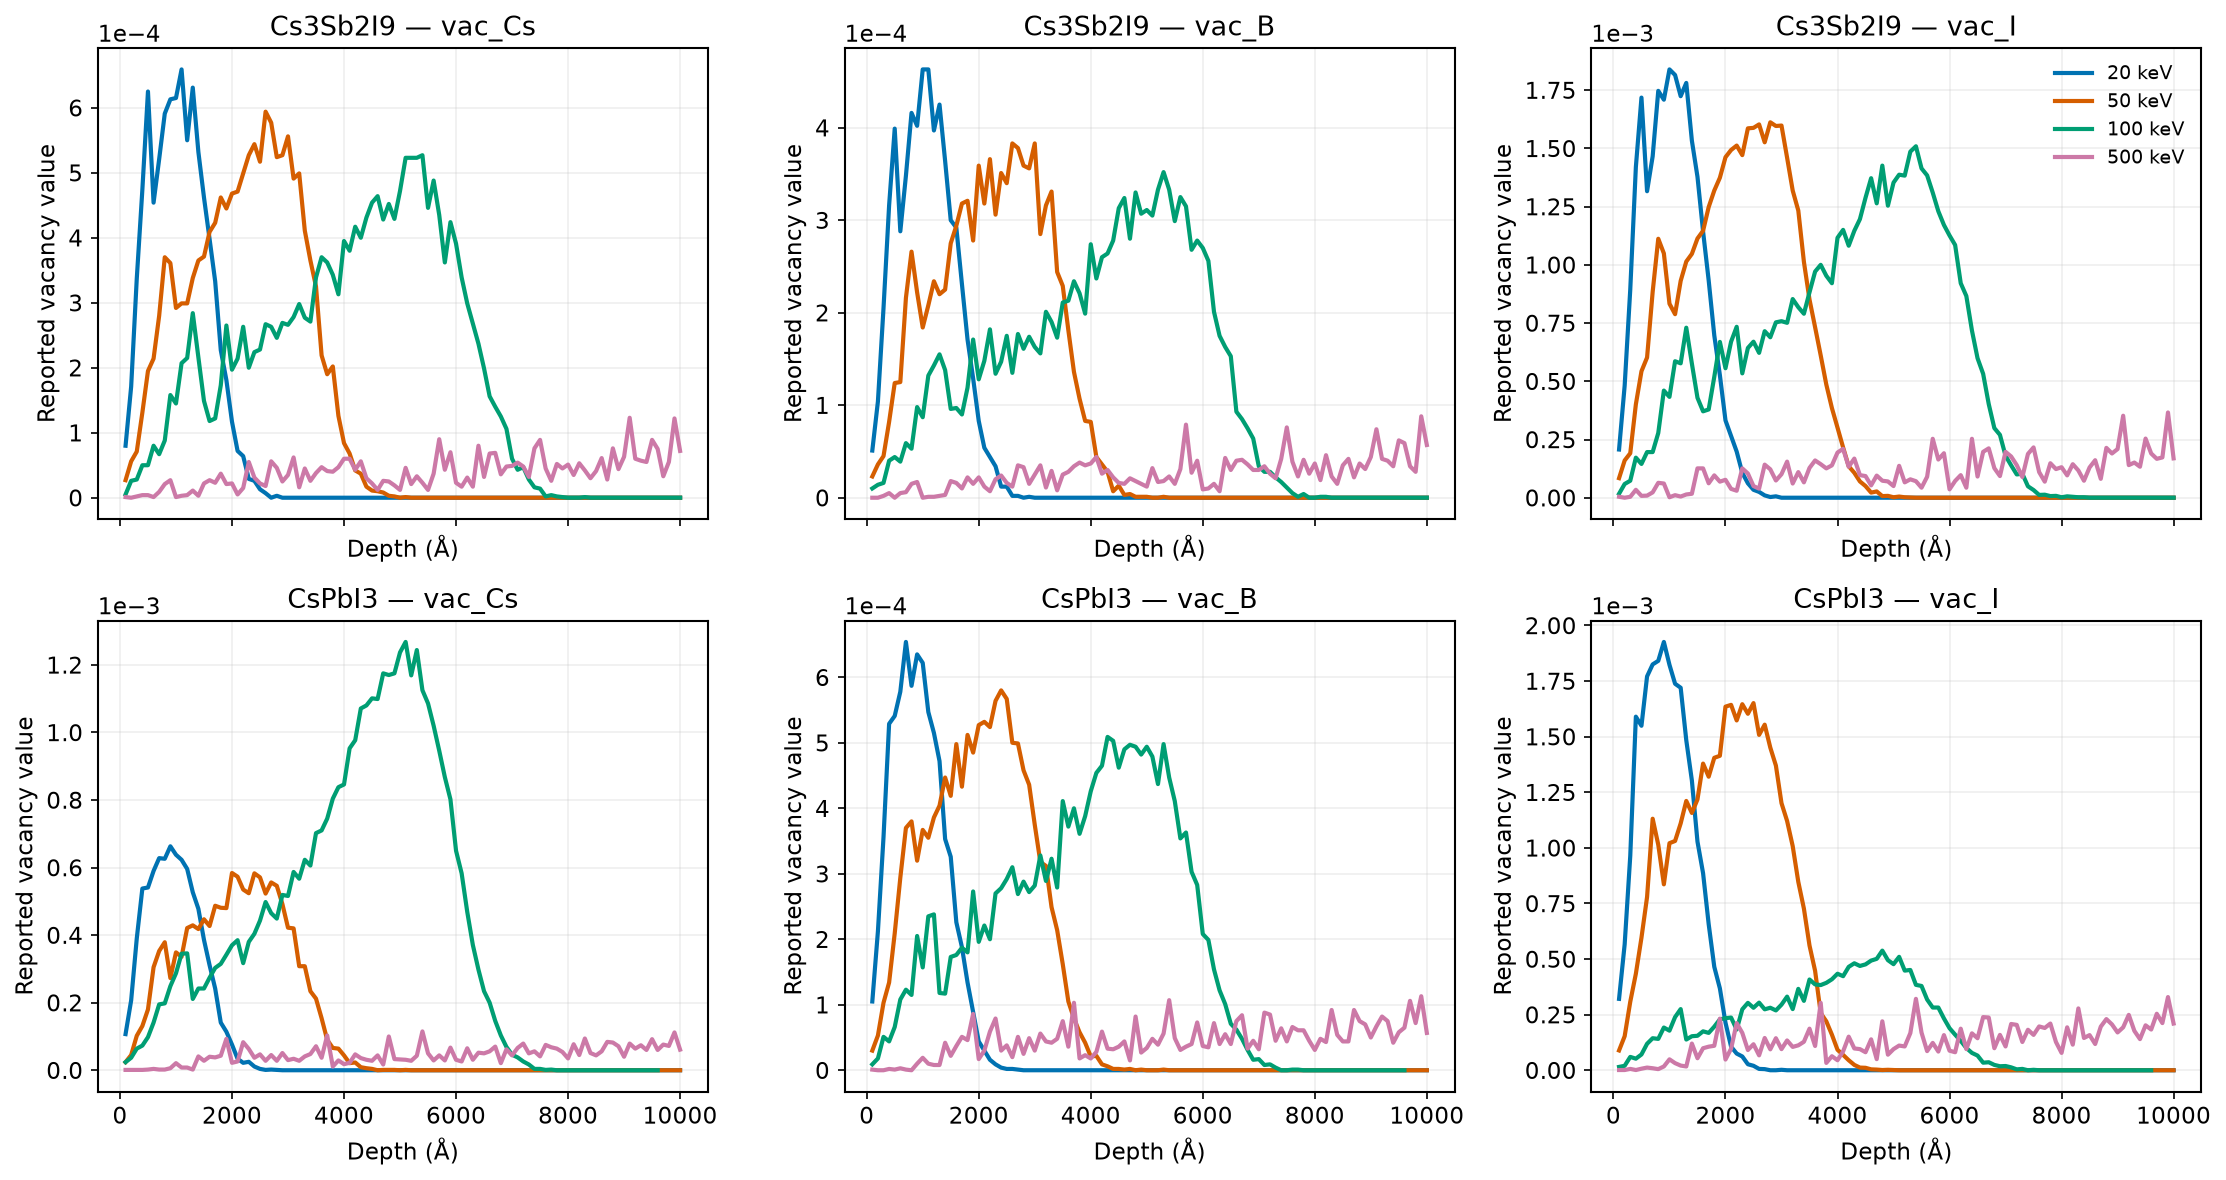

Saved: Figure_1_Vacancy_Profiles


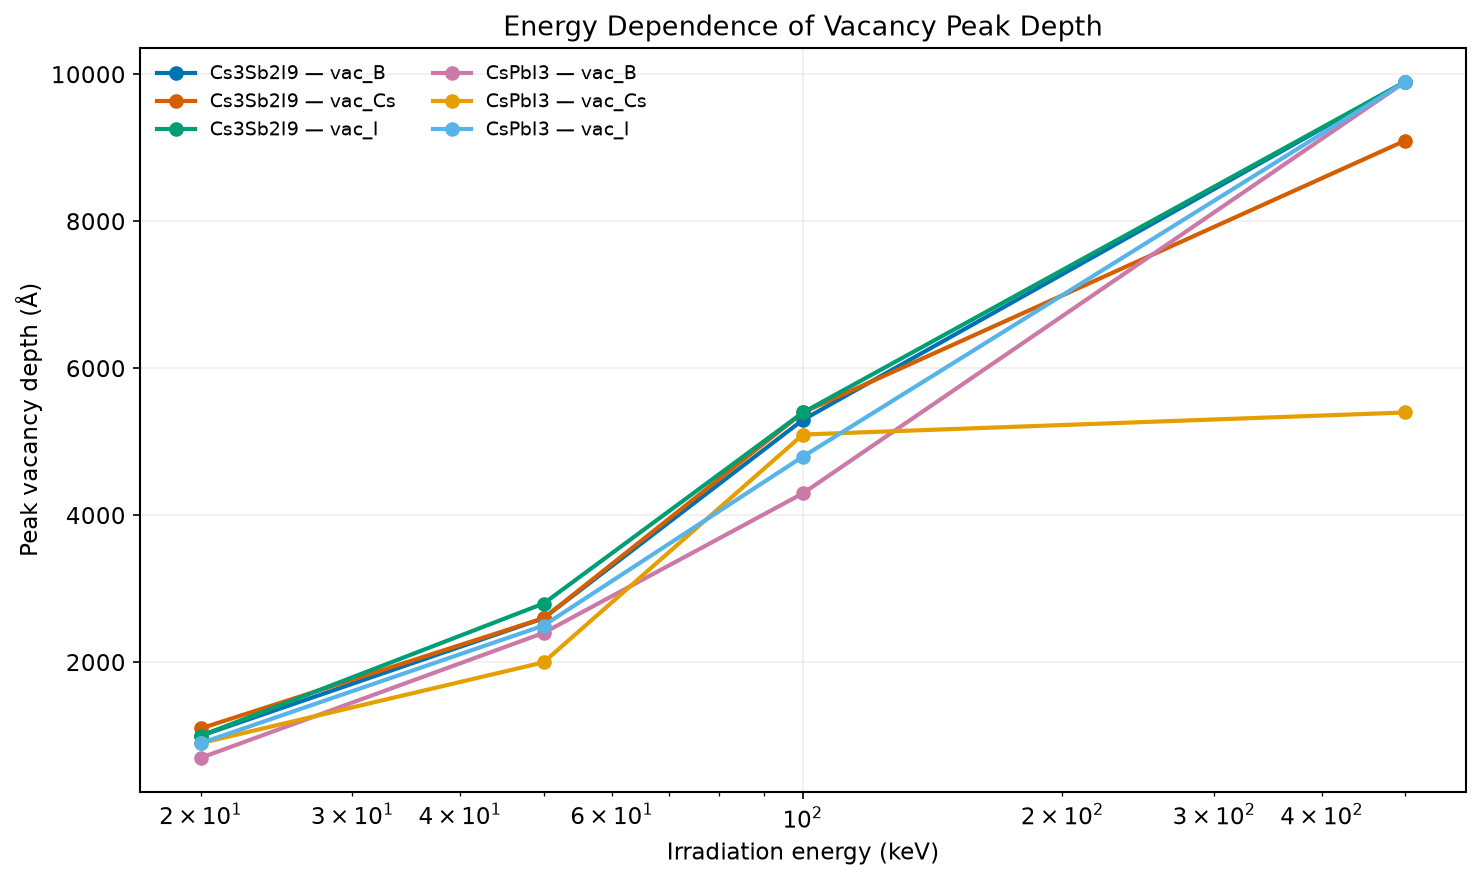

Saved: Figure_2_Peak_Depth


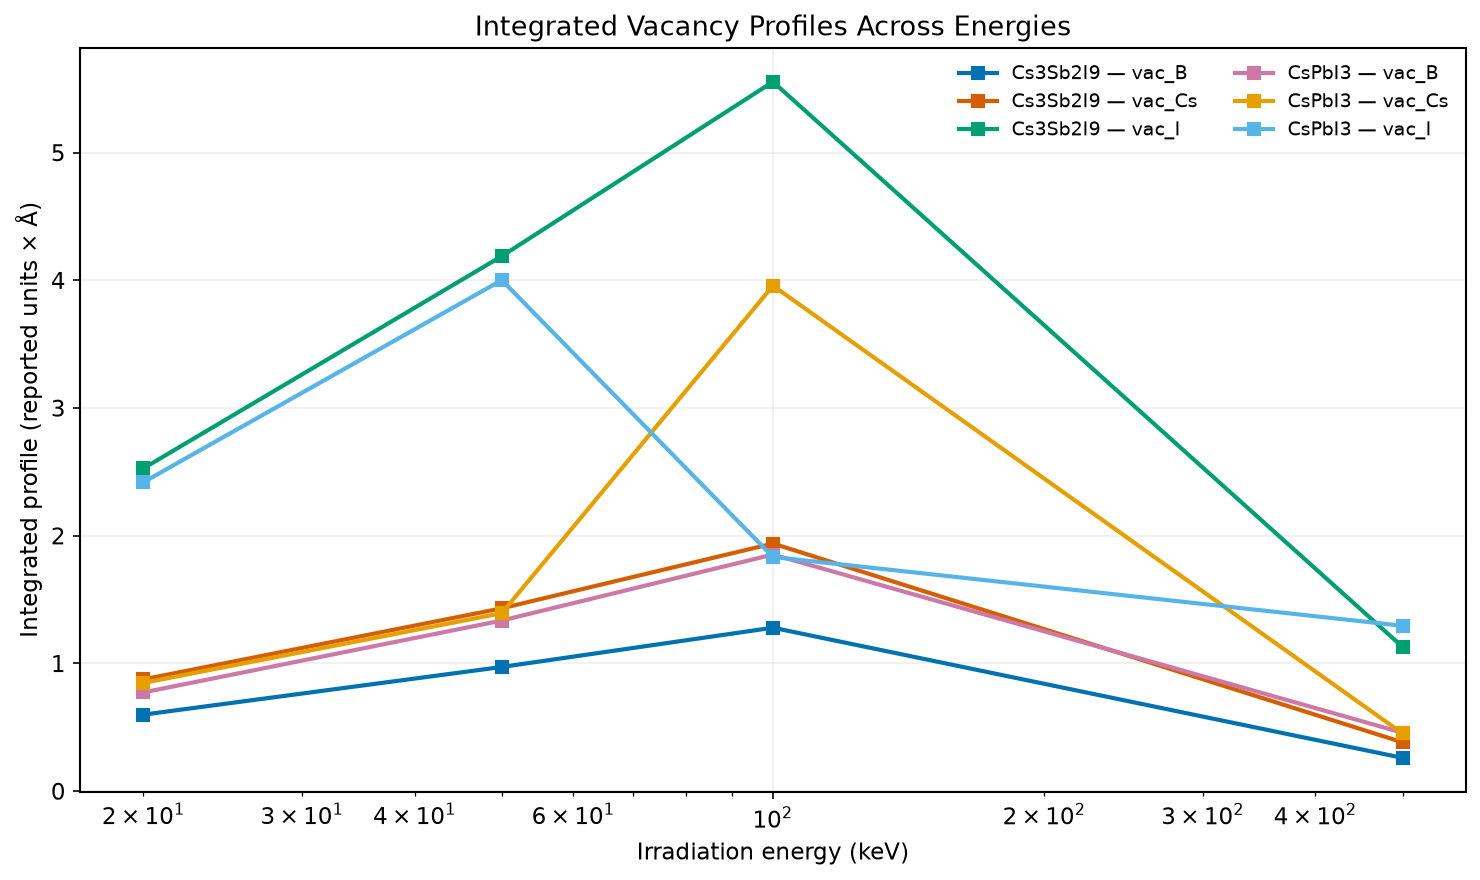

Saved: Figure_3_Integrated_Profiles


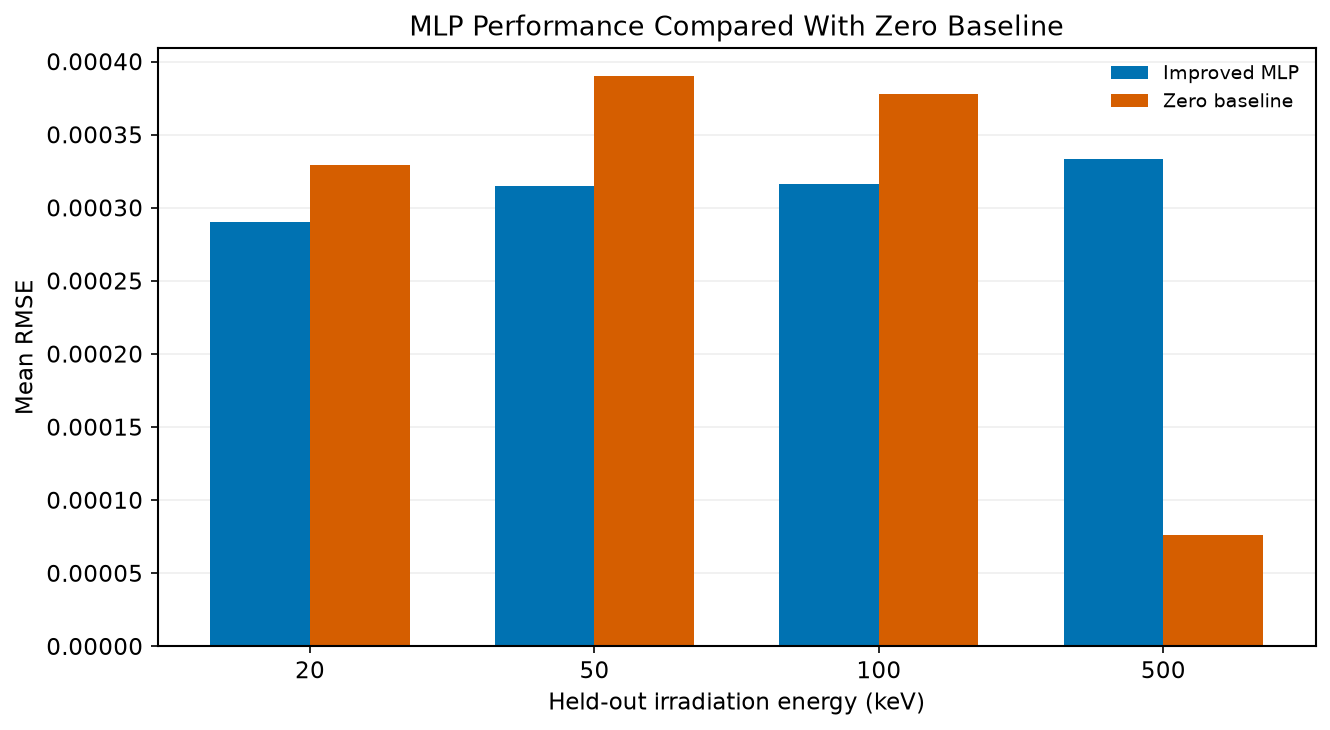

Saved: Figure_4_Model_Performance


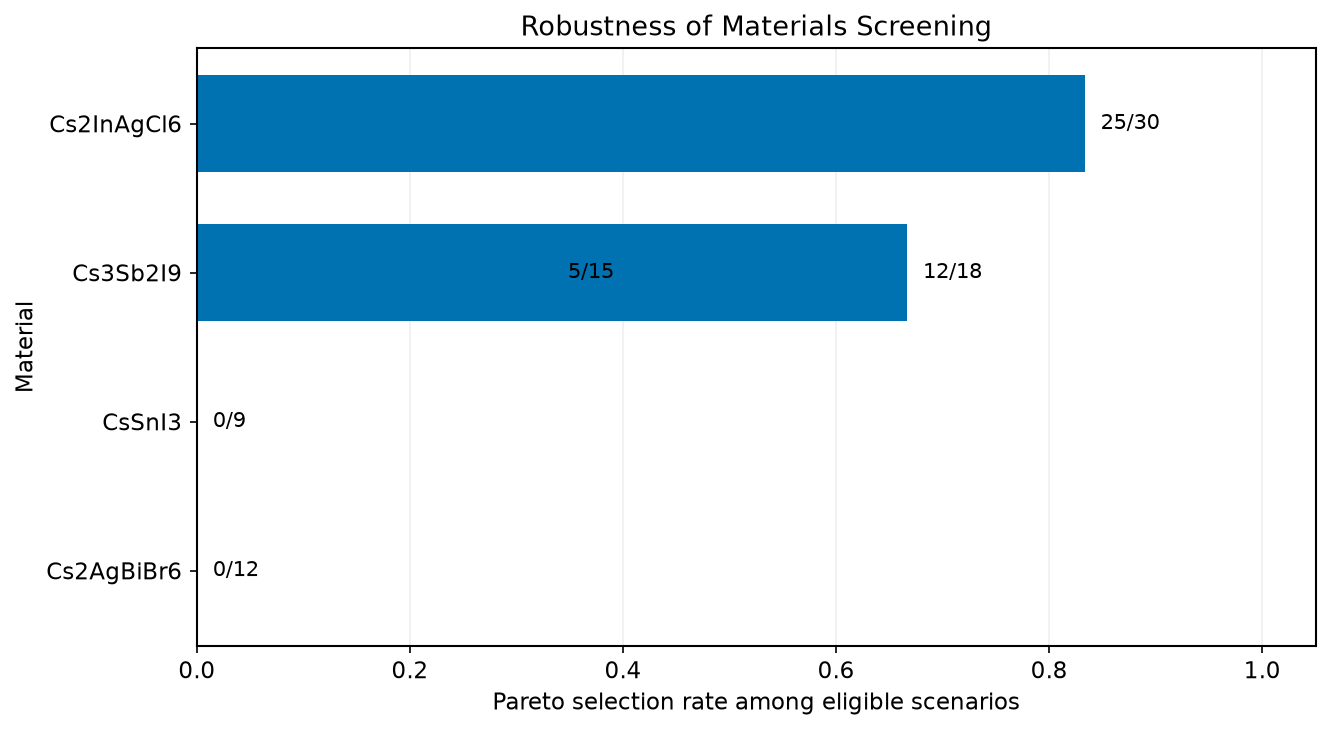

Saved: Figure_5_Pareto_Robustness
Exported: Model_Performance.csv
Exported: Heldout_Evaluation.csv
Exported: Pareto_Robustness.csv
Exported: Pareto_Results.csv
Exported: Pareto_Sensitivity.csv

PAPER RESULTS EXPORT COMPLETE

Output folder:
C:\Users\waqar\OneDrive\Desktop\abihas mlp\Paper_Results

Figures exported: 10 files
Tables exported: 6 files

All available results have been saved.


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import shutil

# ============================================================
# 1. PROJECT FOLDERS
# ============================================================

PROJECT = Path.cwd()

OUTPUT = PROJECT / "Paper_Results"
FIGURES = OUTPUT / "Figures"
TABLES = OUTPUT / "Tables"

FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. FIND AND LOAD DATA AUTOMATICALLY
# ============================================================

def find_csv(*filenames):
    for filename in filenames:
        matches = [
            p for p in PROJECT.rglob(filename)
            if "Paper_Results" not in p.parts
        ]
        if matches:
            return matches[0]
    return None


def load_csv(*filenames):
    path = find_csv(*filenames)

    if path is None:
        print(f"Missing: {filenames[0]}")
        return None

    print(f"Loaded: {path.relative_to(PROJECT)}")
    return pd.read_csv(path)


profiles = load_csv(
    "Abiha_clean_profiles.csv"
)

metrics = load_csv(
    "Abiha_Experiment2_Metrics.csv",
    "02_model_evaluation.csv",
    "Model_Performance.csv"
)

pareto = load_csv(
    "Abiha_Pareto_Robustness_Summary.csv",
    "06_pareto_robustness.csv",
    "Pareto_Robustness.csv"
)

heldout = load_csv(
    "Abiha_heldout_metrics.csv",
    "03_heldout_baseline_comparison.csv",
    "Heldout_Evaluation.csv"
)

pareto_results = load_csv(
    "Abiha_Pareto_Results.csv",
    "04_pareto_results.csv",
    "Pareto_Results.csv"
)

sensitivity = load_csv(
    "Abiha_Corrected_Pareto_Sensitivity.csv",
    "05_pareto_sensitivity.csv",
    "Pareto_Sensitivity.csv"
)

if profiles is None:
    raise FileNotFoundError(
        "Abiha_clean_profiles.csv is required. "
        "Place it inside your project folder."
    )

# ============================================================
# 3. PUBLICATION-QUALITY SETTINGS
# ============================================================

plt.style.use("default")

plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "axes.linewidth": 1,
    "lines.linewidth": 2,
    "legend.fontsize": 9,
    "pdf.fonttype": 42,
    "svg.fonttype": "none"
})

COLORS = [
    "#0072B2",
    "#D55E00",
    "#009E73",
    "#CC79A7",
    "#E69F00",
    "#56B4E9",
    "#333333"
]


def save_figure(name):
    plt.savefig(
        FIGURES / f"{name}.png",
        dpi=600,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.savefig(
        FIGURES / f"{name}.pdf",
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    plt.close()

    print(f"Saved: {name}")


species = ["vac_Cs", "vac_B", "vac_I"]

# ============================================================
# FIGURE 1 — DEPTH-DEPENDENT VACANCY PROFILES
# ============================================================

materials = sorted(profiles["material"].unique())

fig, axes = plt.subplots(
    len(materials),
    3,
    figsize=(15, 4 * len(materials)),
    squeeze=False,
    sharex=True
)

for i, material in enumerate(materials):

    material_df = profiles[
        profiles["material"] == material
    ]

    for j, vacancy in enumerate(species):

        ax = axes[i, j]

        for k, (energy, group) in enumerate(
            material_df.groupby("energy_keV")
        ):

            group = group.sort_values("depth_angstrom")

            ax.plot(
                group["depth_angstrom"],
                group[vacancy],
                label=f"{energy} keV",
                color=COLORS[k % len(COLORS)],
                linewidth=2
            )

        ax.set_title(f"{material} — {vacancy}")
        ax.set_xlabel("Depth (Å)")
        ax.set_ylabel("Reported vacancy value")

        ax.ticklabel_format(
            axis="y",
            style="sci",
            scilimits=(-2, 2)
        )

        ax.grid(alpha=0.2)

        if i == 0 and j == 2:
            ax.legend(frameon=False)

plt.tight_layout()

save_figure("Figure_1_Vacancy_Profiles")


# ============================================================
# 4. CALCULATE PROFILE DESCRIPTORS
# ============================================================

results = []

for (material, energy), group in profiles.groupby(
    ["material", "energy_keV"]
):

    group = group.sort_values("depth_angstrom")

    depth = group["depth_angstrom"].to_numpy()

    for vacancy in species:

        values = group[vacancy].to_numpy()

        peak_index = np.argmax(values)

        results.append({
            "Material": material,
            "Energy_keV": energy,
            "Species": vacancy,
            "Peak_Value": values[peak_index],
            "Peak_Depth_A": depth[peak_index],
            "Profile_Integral": np.trapezoid(
                values, depth
            ),
            "Mean_Value": np.mean(values),
            "Peak_At_Last_Depth": (
                peak_index == len(values) - 1
            )
        })

descriptors = pd.DataFrame(results)

descriptors.to_csv(
    TABLES / "Vacancy_Profile_Descriptors.csv",
    index=False
)


# ============================================================
# FIGURE 2 — PEAK DEPTH VS IRRADIATION ENERGY
# ============================================================

plt.figure(figsize=(10, 6))

for k, ((material, vacancy), group) in enumerate(
    descriptors.groupby(["Material", "Species"])
):

    group = group.sort_values("Energy_keV")

    plt.plot(
        group["Energy_keV"],
        group["Peak_Depth_A"],
        marker="o",
        markersize=6,
        linewidth=2,
        color=COLORS[k % len(COLORS)],
        label=f"{material} — {vacancy}"
    )

plt.xscale("log")
plt.xlabel("Irradiation energy (keV)")
plt.ylabel("Peak vacancy depth (Å)")
plt.title("Energy Dependence of Vacancy Peak Depth")
plt.legend(ncol=2, frameon=False)
plt.grid(alpha=0.2)
plt.tight_layout()

save_figure("Figure_2_Peak_Depth")


# ============================================================
# FIGURE 3 — INTEGRATED VACANCY PROFILES
# ============================================================

plt.figure(figsize=(10, 6))

for k, ((material, vacancy), group) in enumerate(
    descriptors.groupby(["Material", "Species"])
):

    group = group.sort_values("Energy_keV")

    plt.plot(
        group["Energy_keV"],
        group["Profile_Integral"],
        marker="s",
        markersize=6,
        linewidth=2,
        color=COLORS[k % len(COLORS)],
        label=f"{material} — {vacancy}"
    )

plt.xscale("log")
plt.xlabel("Irradiation energy (keV)")
plt.ylabel("Integrated profile (reported units × Å)")
plt.title("Integrated Vacancy Profiles Across Energies")
plt.legend(ncol=2, frameon=False)
plt.grid(alpha=0.2)
plt.tight_layout()

save_figure("Figure_3_Integrated_Profiles")


# ============================================================
# FIGURE 4 — MLP VS ZERO BASELINE
# ============================================================

if metrics is not None:

    selected = metrics[
        metrics["model"].isin([
            "Improved MLP",
            "Zero baseline"
        ])
    ].copy()

    if not selected.empty:

        performance = (
            selected
            .groupby(["energy_keV", "model"])["RMSE"]
            .mean()
            .unstack()
        )

        models = [
            m for m in ["Improved MLP", "Zero baseline"]
            if m in performance.columns
        ]

        energies = performance.index.to_list()
        x = np.arange(len(energies))
        width = 0.35

        fig, ax = plt.subplots(figsize=(9, 5))

        for i, model in enumerate(models):

            offset = (i - (len(models) - 1) / 2) * width

            ax.bar(
                x + offset,
                performance[model],
                width,
                label=model,
                color=COLORS[i]
            )

        ax.set_xticks(x)
        ax.set_xticklabels(energies)
        ax.set_xlabel("Held-out irradiation energy (keV)")
        ax.set_ylabel("Mean RMSE")
        ax.set_title(
            "MLP Performance Compared With Zero Baseline"
        )

        ax.legend(frameon=False)
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)

        plt.tight_layout()

        save_figure("Figure_4_Model_Performance")

    else:
        print("Figure 4 skipped: required model names not found.")

else:
    print("Figure 4 skipped: model metrics not available.")


# ============================================================
# FIGURE 5 — PARETO SCREENING ROBUSTNESS
# ============================================================

if pareto is not None:

    pareto = pareto.sort_values(
        "selection_rate",
        ascending=True
    )

    fig, ax = plt.subplots(figsize=(9, 5))

    bars = ax.barh(
        pareto["formula"],
        pareto["selection_rate"],
        color=COLORS[0],
        height=0.65
    )

    for bar, row in zip(bars, pareto.itertuples()):

        ax.text(
            bar.get_width() + 0.015,
            bar.get_y() + bar.get_height() / 2,
            f"{row.pareto_scenarios}/{row.eligible_scenarios}",
            va="center",
            fontsize=10
        )

    ax.set_xlim(0, 1.05)
    ax.set_xlabel(
        "Pareto selection rate among eligible scenarios"
    )
    ax.set_ylabel("Material")
    ax.set_title("Robustness of Materials Screening")
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

    plt.tight_layout()

    save_figure("Figure_5_Pareto_Robustness")

else:
    print("Figure 5 skipped: Pareto results not available.")


# ============================================================
# 5. EXPORT ALL AVAILABLE TABLES
# ============================================================

export_tables = {
    "Model_Performance.csv": metrics,
    "Heldout_Evaluation.csv": heldout,
    "Pareto_Robustness.csv": pareto,
    "Pareto_Results.csv": pareto_results,
    "Pareto_Sensitivity.csv": sensitivity
}

for filename, dataframe in export_tables.items():

    if dataframe is not None:

        dataframe.to_csv(
            TABLES / filename,
            index=False
        )

        print(f"Exported: {filename}")


# ============================================================
# 6. CREATE A RESULTS README
# ============================================================

readme = """
# Research Results — Radiation-Induced Vacancy Prediction

## Figures

Figure 1: Depth-dependent vacancy profiles for the studied materials.

Figure 2: Relationship between irradiation energy and peak vacancy depth.

Figure 3: Integrated vacancy profiles across irradiation energies.

Figure 4: MLP prediction error compared with the zero baseline.

Figure 5: Robustness of computational material screening.

## Tables

- Vacancy profile descriptors
- Model performance
- Held-out energy evaluation
- Pareto screening results
- Screening sensitivity analysis
- Pareto robustness

## Important Notes

The integrated vacancy profile represents the numerical integral
of the reported vacancy values over depth. Its physical interpretation
depends on the original simulation units and normalization.

The material-screening results do not establish comparative
radiation resistance for materials without irradiation data.

Figures are exported in 600 DPI PNG and vector PDF formats.
"""

(OUTPUT / "README.md").write_text(
    readme.strip(),
    encoding="utf-8"
)


# ============================================================
# 7. FINAL SUMMARY
# ============================================================

figure_files = list(FIGURES.glob("*"))
table_files = list(TABLES.glob("*.csv"))

print("\n" + "=" * 55)
print("PAPER RESULTS EXPORT COMPLETE")
print("=" * 55)

print(f"\nOutput folder:\n{OUTPUT.resolve()}")

print(f"\nFigures exported: {len(figure_files)} files")
print(f"Tables exported: {len(table_files)} files")

print("\nAll available results have been saved.")

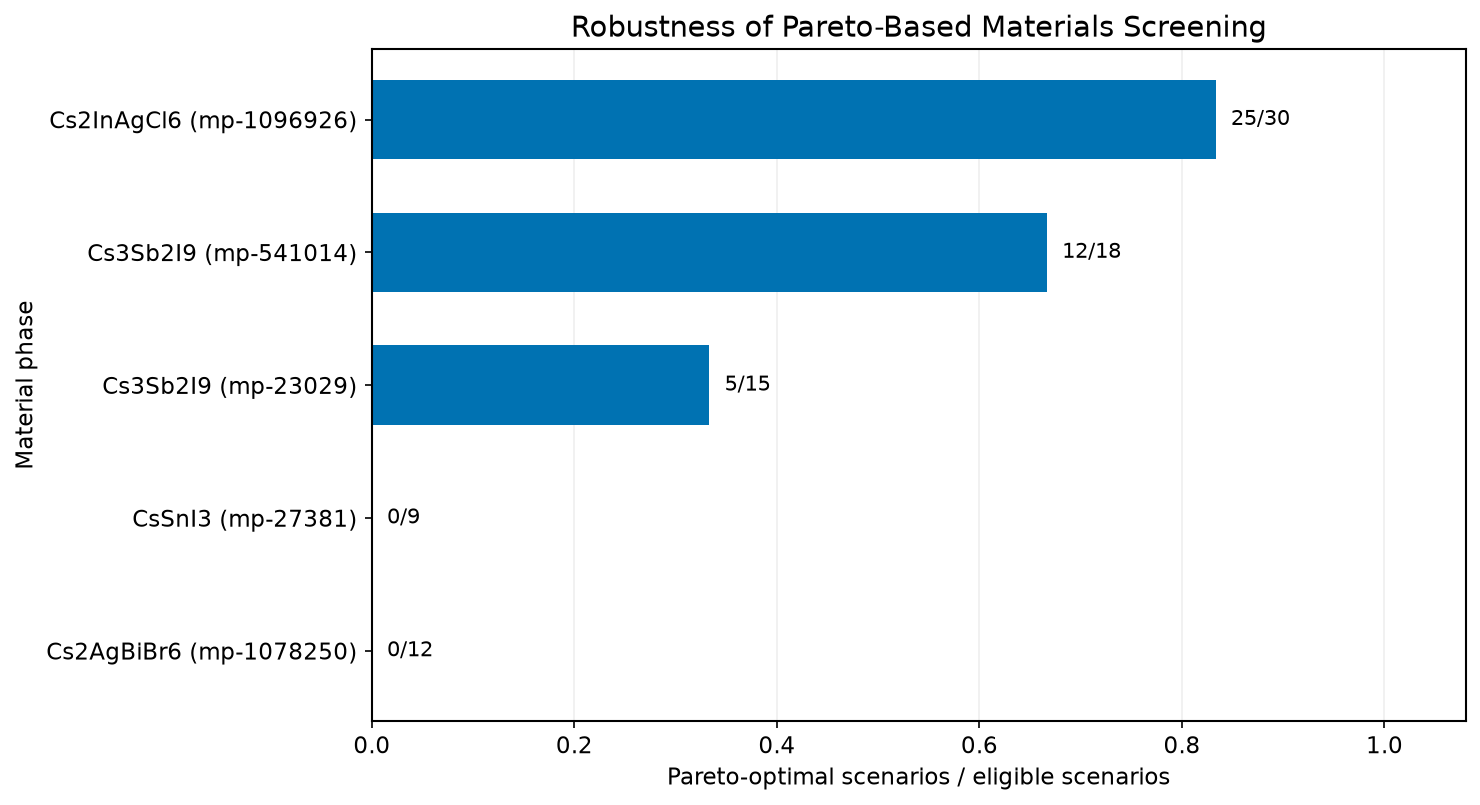

Corrected Figure 5 saved successfully!
C:\Users\waqar\OneDrive\Desktop\abihas mlp\Paper_Results\Figures


In [16]:
# ============================================================
# CORRECTED FIGURE 5 — PARETO SCREENING ROBUSTNESS
# ============================================================

import matplotlib.pyplot as plt
from pathlib import Path

# Output folder
FIGURES = Path.cwd() / "Paper_Results" / "Figures"
FIGURES.mkdir(parents=True, exist_ok=True)

# Prepare data
plot_df = pareto.copy()

plot_df["label"] = (
    plot_df["formula"] +
    " (" +
    plot_df["material_id"] +
    ")"
)

plot_df = plot_df.sort_values(
    "selection_rate",
    ascending=True
)

# Generate figure
fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.barh(
    plot_df["label"],
    plot_df["selection_rate"],
    color="#0072B2",
    height=0.6
)

# Add scenario counts
for bar, row in zip(bars, plot_df.itertuples()):

    ax.text(
        bar.get_width() + 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{row.pareto_scenarios}/{row.eligible_scenarios}",
        va="center",
        fontsize=10
    )

ax.set_xlim(0, 1.08)

ax.set_xlabel(
    "Pareto-optimal scenarios / eligible scenarios"
)

ax.set_ylabel("Material phase")

ax.set_title(
    "Robustness of Pareto-Based Materials Screening",
    fontsize=14
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

# Save corrected figure
plt.savefig(
    FIGURES / "Figure_5_Pareto_Robustness.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    FIGURES / "Figure_5_Pareto_Robustness.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close()

print("Corrected Figure 5 saved successfully!")
print(FIGURES.resolve())